# 📊 Análisis Exploratorio: Mercado Laboral de IA Generativa

**Objetivo:** Explorar y comprender el mercado laboral de Inteligencia Artificial y IA Generativa.

**Dataset:** Ofertas de empleo filtradas por keywords relacionados con AI/ML/GenAI.

---

In [1]:
# 📦 Importaciones y Configuración
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
import ast
import warnings

# Configuración de estilo
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="husl")
plt.rcParams["figure.figsize"] = (14, 7)
plt.rcParams["font.size"] = 12
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

# Rutas
PROJECT_DIR = Path("..").resolve()
TRAIN_PATH = PROJECT_DIR / "data" / "processed" / "train.csv"
TEST_PATH = PROJECT_DIR / "data" / "processed" / "test.csv"

print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


## 1. 📥 Carga de Datos

In [2]:
# Cargar datasets
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

# Combinar para análisis exploratorio completo
df = pd.concat([df_train, df_test], ignore_index=True)

print(f"📂 Datos cargados:")
print(f"   • Train: {len(df_train):,} ofertas")
print(f"   • Test: {len(df_test):,} ofertas")
print(f"   • Total: {len(df):,} ofertas")
print(f"   • Columnas: {df.shape[1]}")
print(f"\n📋 Columnas disponibles: {list(df.columns)}")

📂 Datos cargados:
   • Train: 2,780 ofertas
   • Test: 696 ofertas
   • Total: 3,476 ofertas
   • Columnas: 7

📋 Columnas disponibles: ['job_id', 'title', 'description', 'max_salary', 'pay_period', 'formatted_work_type', 'skills']


In [3]:
# Vista previa del dataset
df.head()

,job_id,title,description,max_salary,pay_period,formatted_work_type,skills
0,3904718968,"Manager, Analytics & Insights",\n\nPhreesia is looking for an Analytics & Ins...,NaN,NaN,Full-time,"['Research', 'Analyst', 'Information Technology']"
1,3900941781,VP of Marketing-AI,We are assisting a growing Gen AI startup with...,250000.0,YEARLY,Full-time,['Marketing']
2,3905257175,Patent Attorney,Title: Patent Attorney (Entrepreneurial-Minded...,700000.0,YEARLY,Full-time,"['Legal', 'Business Development', 'Consulting']"
3,3903828695,Implementation Specialist I,ADP is hiring an Implementation Specialist. \n...,27.4,HOURLY,Full-time,"['Customer Service', 'Accounting/Auditing']"
4,3890893537,Part-Time Remote Project Data Contributor (No ...,Position: Project Data ContributorProject Loca...,NaN,NaN,Contract,"['Information Technology', 'Art/Creative', 'Wr..."


## 2. 🔍 Calidad de Datos

In [4]:
# Análisis de valores faltantes
missing_data = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

quality_df = pd.DataFrame({
    'Columna': df.columns,
    'Valores Faltantes': missing_data.values,
    'Porcentaje (%)': missing_pct.values
}).sort_values('Porcentaje (%)', ascending=False)

print("📊 Análisis de Calidad de Datos:\n")
print(quality_df.to_string(index=False))
print(f"\n💰 Ofertas con salario disponible: {df['max_salary'].notna().sum():,} ({(df['max_salary'].notna().mean()*100):.1f}%)")

📊 Análisis de Calidad de Datos:

            Columna  Valores Faltantes  Porcentaje (%)
         max_salary               2296           66.05
         pay_period               2224           63.98
             skills                 62            1.78
        description                  0            0.00
              title                  0            0.00
             job_id                  0            0.00
formatted_work_type                  0            0.00

💰 Ofertas con salario disponible: 1,180 (33.9%)


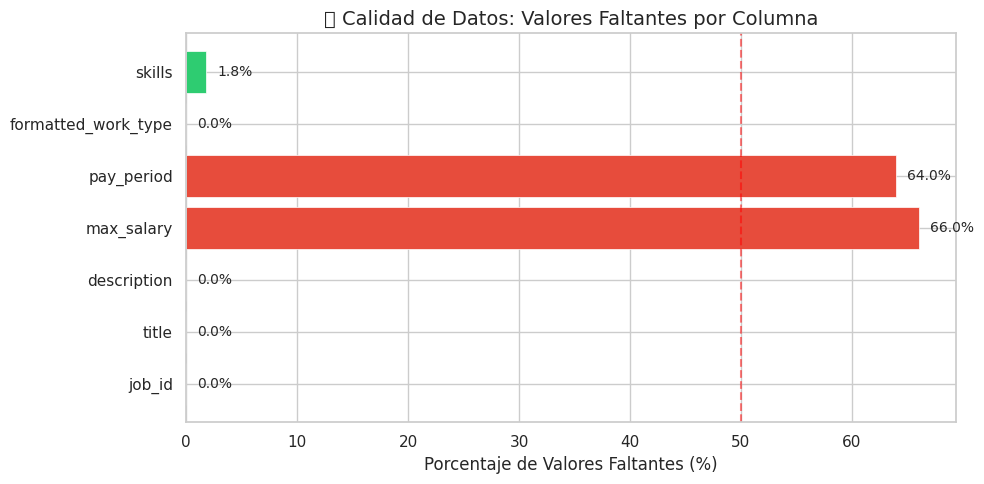

In [5]:
# Visualización de datos faltantes
fig, ax = plt.subplots(figsize=(10, 5))

colors = ['#2ecc71' if pct < 10 else '#f39c12' if pct < 50 else '#e74c3c' for pct in missing_pct]
bars = ax.barh(df.columns, missing_pct.values, color=colors, edgecolor='white', linewidth=0.5)

ax.set_xlabel('Porcentaje de Valores Faltantes (%)')
ax.set_title('🔍 Calidad de Datos: Valores Faltantes por Columna')
ax.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='50% threshold')

# Añadir etiquetas de porcentaje
for bar, pct in zip(bars, missing_pct.values):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
            f'{pct:.1f}%', va='center', fontsize=10)

plt.tight_layout()
plt.show()

## 3. 🏷️ Análisis de Títulos de Trabajo

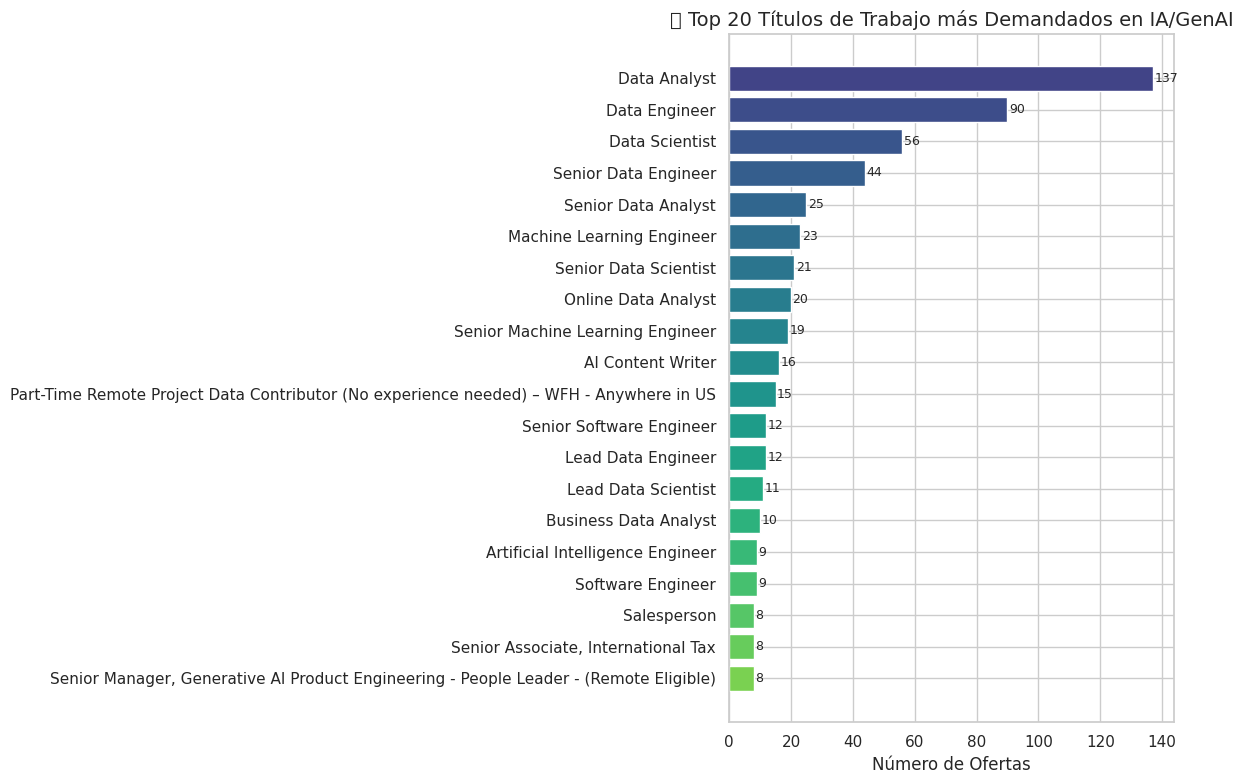


📈 Diversidad de roles: 2,419 títulos únicos


In [6]:
# Top 20 títulos más comunes
title_counts = df['title'].value_counts().head(20)

fig, ax = plt.subplots(figsize=(12, 8))
colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(title_counts)))

bars = ax.barh(title_counts.index[::-1], title_counts.values[::-1], color=colors[::-1])
ax.set_xlabel('Número de Ofertas')
ax.set_title('🏆 Top 20 Títulos de Trabajo más Demandados en IA/GenAI')

# Añadir etiquetas
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2, 
            f'{int(width)}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print(f"\n📈 Diversidad de roles: {df['title'].nunique():,} títulos únicos")

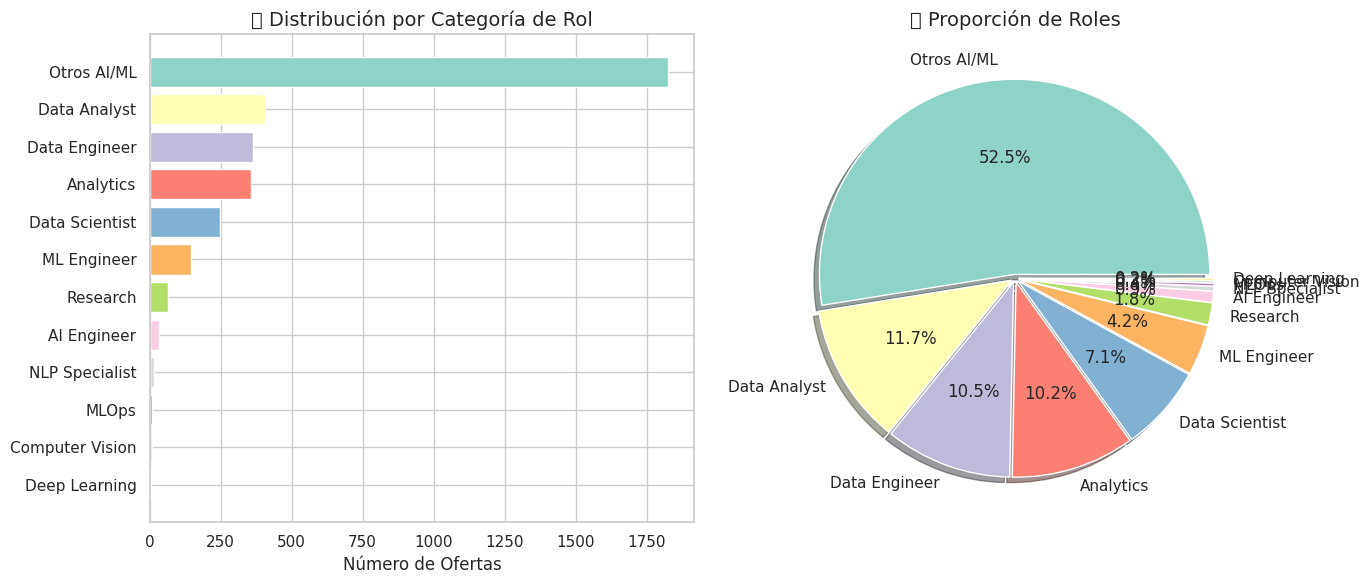

In [7]:
# Análisis de palabras clave en títulos
def categorize_job(title):
    title_lower = str(title).lower()
    if 'data scientist' in title_lower:
        return 'Data Scientist'
    elif 'data engineer' in title_lower:
        return 'Data Engineer'
    elif 'data analyst' in title_lower:
        return 'Data Analyst'
    elif 'machine learning' in title_lower or 'ml engineer' in title_lower:
        return 'ML Engineer'
    elif 'ai engineer' in title_lower:
        return 'AI Engineer'
    elif 'nlp' in title_lower or 'natural language' in title_lower:
        return 'NLP Specialist'
    elif 'computer vision' in title_lower or 'cv engineer' in title_lower:
        return 'Computer Vision'
    elif 'mlops' in title_lower:
        return 'MLOps'
    elif 'research' in title_lower and ('scientist' in title_lower or 'engineer' in title_lower):
        return 'Research'
    elif 'analytics' in title_lower:
        return 'Analytics'
    elif 'deep learning' in title_lower:
        return 'Deep Learning'
    else:
        return 'Otros AI/ML'

df['job_category'] = df['title'].apply(categorize_job)

# Visualización
category_counts = df['job_category'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico de barras
colors = plt.cm.Set3(np.linspace(0, 1, len(category_counts)))
axes[0].barh(category_counts.index[::-1], category_counts.values[::-1], color=colors[::-1])
axes[0].set_xlabel('Número de Ofertas')
axes[0].set_title('📊 Distribución por Categoría de Rol')

# Pie chart
explode = [0.02] * len(category_counts)
axes[1].pie(category_counts.values, labels=category_counts.index, autopct='%1.1f%%', 
            colors=colors, explode=explode, shadow=True)
axes[1].set_title('🥧 Proporción de Roles')

plt.tight_layout()
plt.show()

## 4. 💰 Análisis de Salarios

In [8]:
# Filtrar ofertas con salario válido (asumiendo anual > $20k)
df_salary = df[(df['max_salary'].notna()) & (df['max_salary'] > 20000) & (df['max_salary'] < 500000)].copy()

print(f"💰 Ofertas con salario válido: {len(df_salary):,}")
print(f"\n📊 Estadísticas de Salario Máximo:")
print(df_salary['max_salary'].describe().apply(lambda x: f"${x:,.0f}" if x > 100 else f"{x:.2f}"))

💰 Ofertas con salario válido: 969

📊 Estadísticas de Salario Máximo:
count        $969
mean     $189,838
std       $69,678
min       $40,000
25%      $139,620
50%      $180,000
75%      $234,500
max      $472,900
Name: max_salary, dtype: object


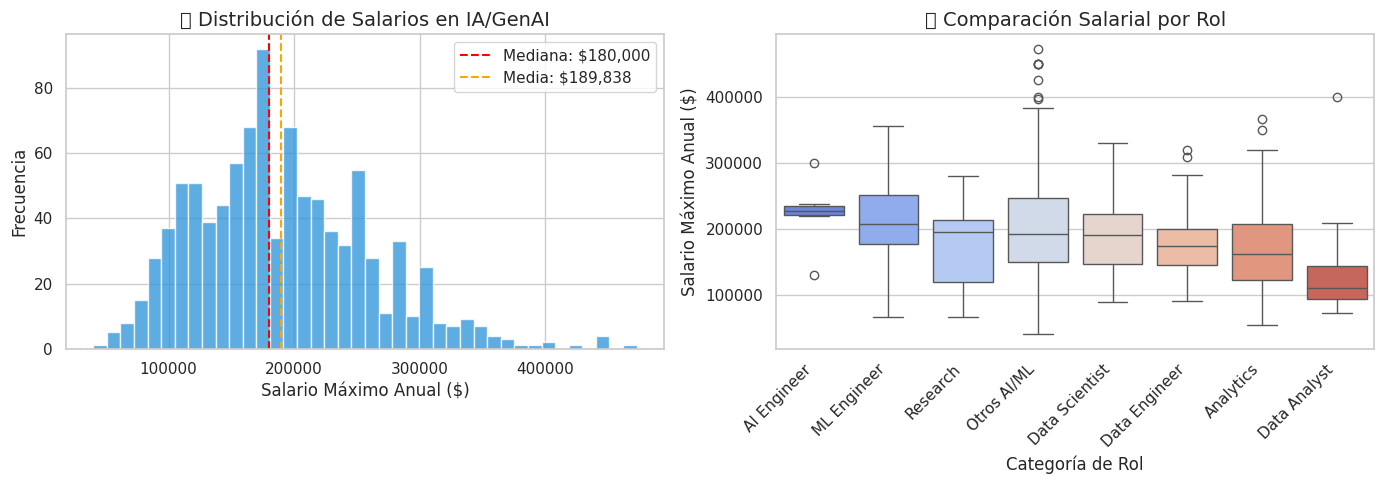

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de salarios
axes[0].hist(df_salary['max_salary'], bins=40, color='#3498db', edgecolor='white', alpha=0.8)
axes[0].axvline(df_salary['max_salary'].median(), color='red', linestyle='--', 
                label=f'Mediana: ${df_salary["max_salary"].median():,.0f}')
axes[0].axvline(df_salary['max_salary'].mean(), color='orange', linestyle='--', 
                label=f'Media: ${df_salary["max_salary"].mean():,.0f}')
axes[0].set_xlabel('Salario Máximo Anual ($)')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('📊 Distribución de Salarios en IA/GenAI')
axes[0].legend()

# Box plot por categoría
top_categories = df_salary['job_category'].value_counts().head(8).index
df_salary_top = df_salary[df_salary['job_category'].isin(top_categories)]

category_order = df_salary_top.groupby('job_category')['max_salary'].median().sort_values(ascending=False).index
sns.boxplot(data=df_salary_top, x='job_category', y='max_salary', order=category_order, ax=axes[1], palette='coolwarm')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_xlabel('Categoría de Rol')
axes[1].set_ylabel('Salario Máximo Anual ($)')
axes[1].set_title('💵 Comparación Salarial por Rol')

plt.tight_layout()
plt.show()

In [10]:
# Tabla de salarios por categoría
salary_by_category = df_salary.groupby('job_category')['max_salary'].agg(['median', 'mean', 'min', 'max', 'count'])
salary_by_category = salary_by_category.sort_values('median', ascending=False)
salary_by_category.columns = ['Mediana', 'Media', 'Mínimo', 'Máximo', 'N° Ofertas']

# Formatear como moneda
for col in ['Mediana', 'Media', 'Mínimo', 'Máximo']:
    salary_by_category[col] = salary_by_category[col].apply(lambda x: f"${x:,.0f}")

print("💵 Tabla de Salarios por Categoría de Rol:\n")
salary_by_category

💵 Tabla de Salarios por Categoría de Rol:



,Mediana,Media,Mínimo,Máximo,N° Ofertas
job_category,,,,,
Computer Vision,"$248,000","$248,000","$246,000","$250,000",2
NLP Specialist,"$230,350","$230,350","$200,700","$260,000",2
AI Engineer,"$227,500","$223,645","$130,000","$300,000",6
MLOps,"$225,000","$220,000","$180,000","$250,000",4
ML Engineer,"$207,000","$221,608","$66,295","$355,000",46
Deep Learning,"$202,730","$207,672","$202,730","$222,500",4
Research,"$195,200","$175,979","$67,000","$280,000",21
Otros AI/ML,"$192,000","$199,387","$40,000","$472,900",559
Data Scientist,"$190,758","$190,389","$88,926","$329,333",74


## 5. 🛠️ Análisis de Habilidades

In [11]:
# Procesar habilidades
def parse_skills(skill_str):
    if pd.isna(skill_str):
        return []
    try:
        if isinstance(skill_str, str):
            return ast.literal_eval(skill_str)
        return []
    except:
        return []

df['skills_list'] = df['skills'].apply(parse_skills)

# Aplanar lista de habilidades
all_skills = [skill for sublist in df['skills_list'] for skill in sublist]
skill_counts = Counter(all_skills)

print(f"🛠️ Total de menciones de habilidades: {len(all_skills):,}")
print(f"📚 Habilidades únicas: {len(skill_counts):,}")

🛠️ Total de menciones de habilidades: 6,087
📚 Habilidades únicas: 35


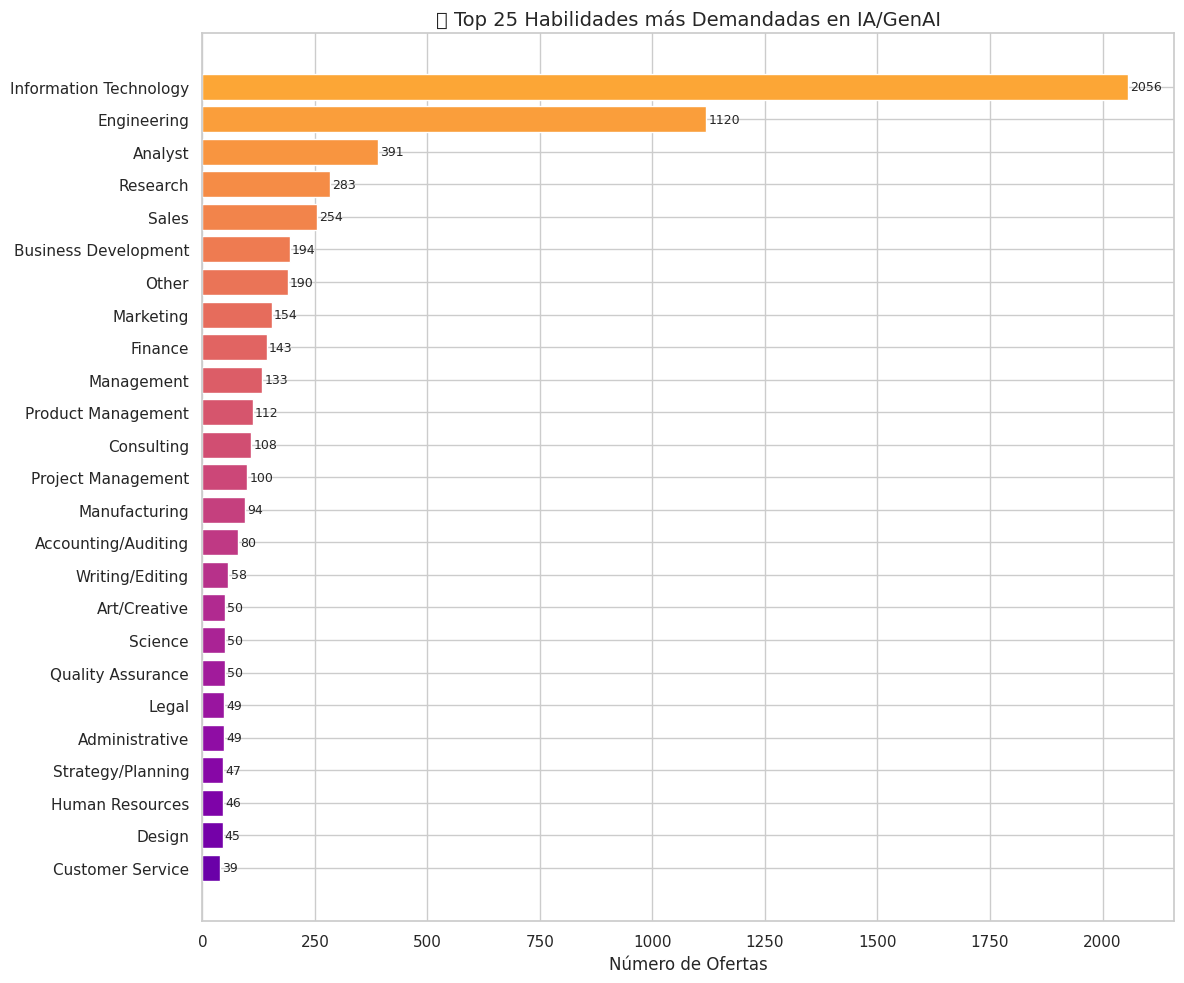

In [12]:
# Top 25 habilidades
top_skills = skill_counts.most_common(25)

fig, ax = plt.subplots(figsize=(12, 10))
skills_names = [s[0] for s in top_skills][::-1]
skills_counts = [s[1] for s in top_skills][::-1]

colors = plt.cm.plasma(np.linspace(0.2, 0.8, len(skills_names)))
bars = ax.barh(skills_names, skills_counts, color=colors)

ax.set_xlabel('Número de Ofertas')
ax.set_title('🏆 Top 25 Habilidades más Demandadas en IA/GenAI')

# Etiquetas
for bar in bars:
    width = bar.get_width()
    ax.text(width + 5, bar.get_y() + bar.get_height()/2, 
            f'{int(width)}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

## 6. 🏢 Tipos de Trabajo

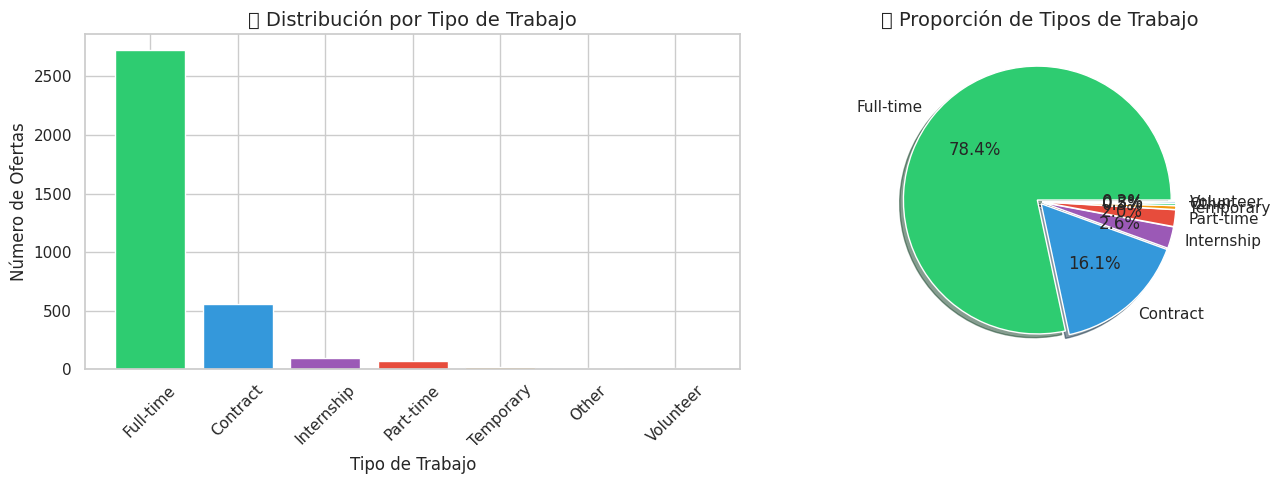

In [13]:
# Análisis de tipos de trabajo
work_type_counts = df['formatted_work_type'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barras
colors = ['#2ecc71', '#3498db', '#9b59b6', '#e74c3c', '#f39c12']
axes[0].bar(work_type_counts.index, work_type_counts.values, color=colors[:len(work_type_counts)])
axes[0].set_xlabel('Tipo de Trabajo')
axes[0].set_ylabel('Número de Ofertas')
axes[0].set_title('🏢 Distribución por Tipo de Trabajo')
axes[0].tick_params(axis='x', rotation=45)

# Pie
axes[1].pie(work_type_counts.values, labels=work_type_counts.index, autopct='%1.1f%%',
            colors=colors[:len(work_type_counts)], explode=[0.02]*len(work_type_counts), shadow=True)
axes[1].set_title('📊 Proporción de Tipos de Trabajo')

plt.tight_layout()
plt.show()

## 7. 📋 Resumen Ejecutivo

In [14]:
# Resumen final
print("="*60)
print("📊 RESUMEN EJECUTIVO: Mercado Laboral IA Generativa")
print("="*60)
print(f"""\n
📈 VOLUMEN DE DATOS
   • Total de ofertas analizadas: {len(df):,}
   • Títulos únicos: {df['title'].nunique():,}
   • Ofertas con salario: {df['max_salary'].notna().sum():,} ({(df['max_salary'].notna().mean()*100):.1f}%)

💰 SALARIOS
   • Salario mediano: ${df_salary['max_salary'].median():,.0f}
   • Salario promedio: ${df_salary['max_salary'].mean():,.0f}
   • Rango salarial: ${df_salary['max_salary'].min():,.0f} - ${df_salary['max_salary'].max():,.0f}

🏆 TOP 5 ROLES MÁS DEMANDADOS
""")
for i, (role, count) in enumerate(category_counts.head(5).items(), 1):
    print(f"   {i}. {role}: {count:,} ofertas")

print(f"""\n
🛠️ TOP 5 HABILIDADES MÁS DEMANDADAS
""")
for i, (skill, count) in enumerate(skill_counts.most_common(5), 1):
    print(f"   {i}. {skill}: {count:,} menciones")

print(f"\n" + "="*60)

📊 RESUMEN EJECUTIVO: Mercado Laboral IA Generativa


📈 VOLUMEN DE DATOS
   • Total de ofertas analizadas: 3,476
   • Títulos únicos: 2,419
   • Ofertas con salario: 1,180 (33.9%)

💰 SALARIOS
   • Salario mediano: $180,000
   • Salario promedio: $189,838
   • Rango salarial: $40,000 - $472,900

🏆 TOP 5 ROLES MÁS DEMANDADOS

   1. Otros AI/ML: 1,826 ofertas
   2. Data Analyst: 405 ofertas
   3. Data Engineer: 365 ofertas
   4. Analytics: 356 ofertas
   5. Data Scientist: 247 ofertas


🛠️ TOP 5 HABILIDADES MÁS DEMANDADAS

   1. Information Technology: 2,056 menciones
   2. Engineering: 1,120 menciones
   3. Analyst: 391 menciones
   4. Research: 283 menciones
   5. Sales: 254 menciones



In [15]:
# Guardar dataset enriquecido
df_enriched = df.drop(columns=['skills_list'], errors='ignore')
print(f"\n✅ Análisis completado. Dataset listo para siguiente fase.")
print(f"   Columnas finales: {list(df.columns)}")


✅ Análisis completado. Dataset listo para siguiente fase.
   Columnas finales: ['job_id', 'title', 'description', 'max_salary', 'pay_period', 'formatted_work_type', 'skills', 'job_category', 'skills_list']
